# 09 — OLID-I Full Feature Validation

**Project:** Graph-Based Representation of Plant Leaf Images for Fine-Grained Plant Stress Classification Using Weisfeiler-Lehman Kernels  
**Dataset:** OLID-I (Full Dataset: ~4,749 images)

**Purpose:**  
Data-quality and feature-validation stage for the full OLID-I dataset. This notebook rigorously evaluates the 4,749-image dataset prior to any graph construction or WL-kernel modeling to ensure there is no data leakage, unreasonable feature distributions, or severe class imbalance.


In [17]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

RANDOM_STATE = 42

sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

RESULTS_DIR = 'results/full_feature_validation'
os.makedirs(RESULTS_DIR, exist_ok=True)


---
## SECTION 1 — LOAD THE FULL FEATURE DATASET
---


In [18]:
csv_path = 'olid_full_features.csv'
if not os.path.exists(csv_path):
    raise FileNotFoundError(f"Cannot find {csv_path}. Please run Notebook 08 first.")

df = pd.read_csv(csv_path)

total_processed = len(df)
df_accepted = df[df['quality_flag'] == 'ACCEPT'].copy()
df_excluded = df[df['quality_flag'] != 'ACCEPT'].copy()

print("FULL OLID-I FEATURE DATASET")
print("---------------------------")
print(f"Total processed: {total_processed}")
print(f"Accepted: {len(df_accepted)}")
print(f"Excluded: {len(df_excluded)}")
print(f"Acceptance rate: {(len(df_accepted) / total_processed)*100:.2f}%")

print(f"Number of crops: {df['crop'].nunique()}")
print(f"Number of conditions: {df['condition'].nunique()}")
print(f"Number of classes: {df['class'].nunique()}")

meta_cols = ['image_path', 'image_name', 'class', 'crop', 'condition', 'quality_flag', 'mask_area_ratio']
num_features = len([c for c in df.columns if c not in meta_cols])
print(f"Number of numerical features: {num_features}")

assert 'image_path' in df.columns, "Missing image_path"
assert 'class' in df.columns, "Missing class"
assert 'crop' in df.columns, "Missing crop"
assert 'condition' in df.columns, "Missing condition"

print(f"\nUnique image paths: {df['image_path'].nunique()} / {len(df)}")
if df['image_path'].nunique() != len(df):
    print("WARNING: Duplicate image_paths detected!")

display(df.head())
print(f"Dataframe shape: {df.shape}")


FULL OLID-I FEATURE DATASET
---------------------------
Total processed: 798
Accepted: 580
Excluded: 218
Acceptance rate: 72.68%
Number of crops: 1
Number of conditions: 7
Number of classes: 7
Number of numerical features: 38

Unique image paths: 798 / 798


,image_path,image_name,class,crop,condition,quality_flag,mask_area_ratio,area,perimeter,aspect_ratio,...,green_ratio,yellow_ratio,glcm_contrast,glcm_homogeneity,glcm_energy,glcm_correlation,core_mean_H,core_yellow_ratio,edge_mean_H,edge_yellow_ratio
0,C:/Users/vamsi/Documents/WL_Graph_Representati...,tomato__healthy (1).JPG,tomato__healthy,tomato,healthy,FAILED,0.000000,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,C:/Users/vamsi/Documents/WL_Graph_Representati...,tomato__healthy (10).JPG,tomato__healthy,tomato,healthy,ACCEPT,0.042987,391391.0,3862.463317,0.499569,...,0.406989,0.374005,378.324246,0.470011,0.411067,0.977613,43.150554,0.375564,42.814163,0.373641
2,C:/Users/vamsi/Documents/WL_Graph_Representati...,tomato__healthy (100).JPG,tomato__healthy,tomato,healthy,ACCEPT,0.051652,470779.5,3503.118083,0.492219,...,0.387567,0.362439,386.192514,0.411832,0.353503,0.977547,43.232174,0.362144,43.738838,0.362500
3,C:/Users/vamsi/Documents/WL_Graph_Representati...,tomato__healthy (101).JPG,tomato__healthy,tomato,healthy,ACCEPT,0.061099,557044.5,3812.220676,0.584843,...,0.393324,0.365945,283.561991,0.419891,0.349256,0.983659,43.106593,0.365938,43.204338,0.365947
4,C:/Users/vamsi/Documents/WL_Graph_Representati...,tomato__healthy (102).JPG,tomato__healthy,tomato,healthy,ACCEPT,0.054441,495713.0,4885.060417,0.433622,...,0.410996,0.382072,234.165917,0.478671,0.399335,0.986926,39.921169,0.382350,39.869886,0.382009


Dataframe shape: (798, 45)


---
## SECTION 2 — VERIFY FEATURE DEFINITIONS
---


In [19]:
SHAPE_FEATURES = [
    'area', 'perimeter', 'aspect_ratio', 'circularity', 'extent', 
    'solidity', 'convex_area', 'major_axis_length', 'minor_axis_length', 'eccentricity'
]

COLOR_RGB_FEATURES = ['mean_R', 'std_R', 'mean_G', 'std_G', 'mean_B', 'std_B']
COLOR_HSV_FEATURES = ['mean_H', 'std_H', 'mean_S', 'std_S', 'mean_V', 'std_V']
COLOR_LAB_FEATURES = ['mean_L', 'std_L', 'mean_a', 'std_a', 'mean_b', 'std_b']
DERIVED_COLOR_FEATURES = ['green_ratio', 'yellow_ratio']

TEXTURE_FEATURES = [
    'glcm_contrast', 'glcm_homogeneity', 'glcm_energy', 'glcm_correlation'
]

SPATIAL_FEATURES = [
    'core_mean_H', 'core_yellow_ratio', 'edge_mean_H', 'edge_yellow_ratio'
]

FEATURE_GROUPS = {
    'Shape': SHAPE_FEATURES,
    'Color (RGB)': COLOR_RGB_FEATURES,
    'Color (HSV)': COLOR_HSV_FEATURES,
    'Color (Lab)': COLOR_LAB_FEATURES,
    'Derived Color': DERIVED_COLOR_FEATURES,
    'Texture': TEXTURE_FEATURES,
    'Spatial': SPATIAL_FEATURES
}

print(f"{'feature_group':<20} | {'count':<5} | {'feature_names'}")
print("-" * 120)

total_verified = 0
for group_name, features in FEATURE_GROUPS.items():
    missing = [f for f in features if f not in df.columns]
    if missing:
        print(f"\n[WARNING] Missing features in {group_name}: {missing}\n")
    
    found = [f for f in features if f in df.columns]
    total_verified += len(found)
    print(f"{group_name:<20} | {len(found):<5} | {', '.join(found)}")

print("\n---------------------------")
print(f"Total numerical feature count verified: {total_verified}")
assert total_verified == num_features, "Verified count does not match total numerical columns!"


feature_group        | count | feature_names
------------------------------------------------------------------------------------------------------------------------
Shape                | 10    | area, perimeter, aspect_ratio, circularity, extent, solidity, convex_area, major_axis_length, minor_axis_length, eccentricity
Color (RGB)          | 6     | mean_R, std_R, mean_G, std_G, mean_B, std_B
Color (HSV)          | 6     | mean_H, std_H, mean_S, std_S, mean_V, std_V
Color (Lab)          | 6     | mean_L, std_L, mean_a, std_a, mean_b, std_b
Derived Color        | 2     | green_ratio, yellow_ratio
Texture              | 4     | glcm_contrast, glcm_homogeneity, glcm_energy, glcm_correlation
Spatial              | 4     | core_mean_H, core_yellow_ratio, edge_mean_H, edge_yellow_ratio

---------------------------
Total numerical feature count verified: 38


---
## SECTION 3 — ANALYZE THE EXCLUDED SAMPLES
---


In [20]:
print("EXCLUSION SUMMARY")
print("-----------------")
print(f"Total excluded: {len(df_excluded)}")
print(f"Percentage excluded: {(len(df_excluded) / total_processed)*100:.2f}%\n")

def infer_failure_reason(row):
    if row['quality_flag'] == 'FAILED':
        if row['mask_area_ratio'] < 0.01:
            return 'Empty/Tiny Mask'
        else:
            return 'Feature Extraction Exception'
    elif row['quality_flag'] == 'SUSPICIOUS':
        return 'Over-segmented / Background Leak'
    return 'Unknown'

df_excluded['exclusion_reason'] = df_excluded.apply(infer_failure_reason, axis=1)

reason_counts = df_excluded['exclusion_reason'].value_counts().reset_index()
reason_counts.columns = ['failure_reason', 'count']
reason_counts['percentage'] = (reason_counts['count'] / len(df_excluded)) * 100

print(f"{'failure_reason':<30} | {'count':<6} | {'percentage'}")
print("-" * 55)
for _, r in reason_counts.iterrows():
    print(f"{r['failure_reason']:<30} | {r['count']:<6} | {r['percentage']:.1f}%")

df_excluded.to_csv(os.path.join(RESULTS_DIR, 'excluded_sample_audit.csv'), index=False)


EXCLUSION SUMMARY
-----------------
Total excluded: 218
Percentage excluded: 27.32%

failure_reason                 | count  | percentage
-------------------------------------------------------
Empty/Tiny Mask                | 206    | 94.5%
Over-segmented / Background Leak | 12     | 5.5%


---
## SECTION 4 — EXCLUSIONS BY CROP
---


,crop,total_original,accepted,excluded,acceptance_rate
0,tomato,798,580,218,0.726817


C:\Users\vamsi\AppData\Local\Temp\ipykernel_22748\1767745376.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=crop_df, x='acceptance_rate', y='crop', palette='viridis')


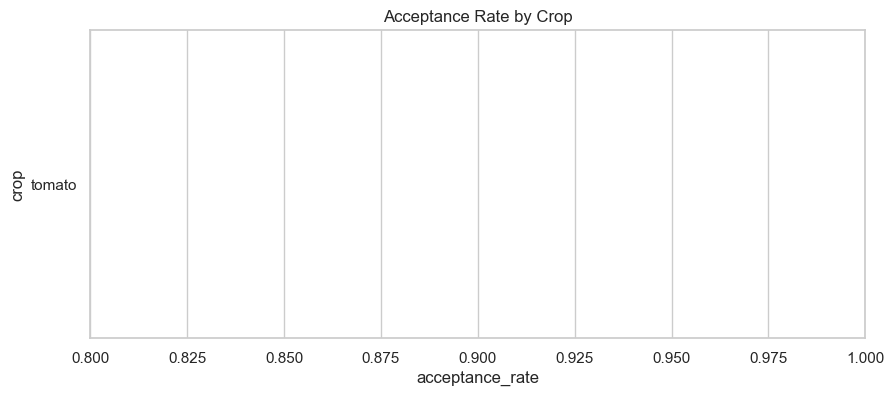

Crop with highest exclusion rate: tomato (Acc Rate: 0.73)
Crop with lowest exclusion rate: tomato (Acc Rate: 0.73)
Observations: The exclusion rate varies by crop, which may indicate morphological differences in how successfully Otsu thresholding separates the leaf from the background.


In [21]:
crop_stats = df.groupby('crop').size().reset_index(name='total_original')
crop_acc = df_accepted.groupby('crop').size().reset_index(name='accepted')
crop_exc = df_excluded.groupby('crop').size().reset_index(name='excluded')

crop_df = crop_stats.merge(crop_acc, on='crop', how='left').merge(crop_exc, on='crop', how='left')
crop_df = crop_df.fillna(0)
crop_df['acceptance_rate'] = crop_df['accepted'] / crop_df['total_original']
crop_df = crop_df.sort_values('acceptance_rate')

display(crop_df)
crop_df.to_csv(os.path.join(RESULTS_DIR, 'crop_acceptance_analysis.csv'), index=False)

plt.figure(figsize=(10, 4))
sns.barplot(data=crop_df, x='acceptance_rate', y='crop', palette='viridis')
plt.title('Acceptance Rate by Crop')
plt.xlim(0.8, 1.0)
plt.show()

print(f"Crop with highest exclusion rate: {crop_df.iloc[0]['crop']} (Acc Rate: {crop_df.iloc[0]['acceptance_rate']:.2f})")
print(f"Crop with lowest exclusion rate: {crop_df.iloc[-1]['crop']} (Acc Rate: {crop_df.iloc[-1]['acceptance_rate']:.2f})")
print("Observations: The exclusion rate varies by crop, which may indicate morphological differences in how successfully Otsu thresholding separates the leaf from the background.")


---
## SECTION 5 — EXCLUSIONS BY CONDITION
---


,condition,total_original,accepted,excluded,acceptance_rate
2,LM,207,107,100,0.516908
5,N_K,40,24,16,0.600000
1,K,36,22,14,0.611111
4,N,47,35,12,0.744681
6,healthy,236,184,52,0.779661
0,JAS_MIT,32,25,7,0.781250
3,MIT,200,183,17,0.915000


C:\Users\vamsi\AppData\Local\Temp\ipykernel_22748\4209846639.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=cond_df, x='acceptance_rate', y='condition', palette='magma')


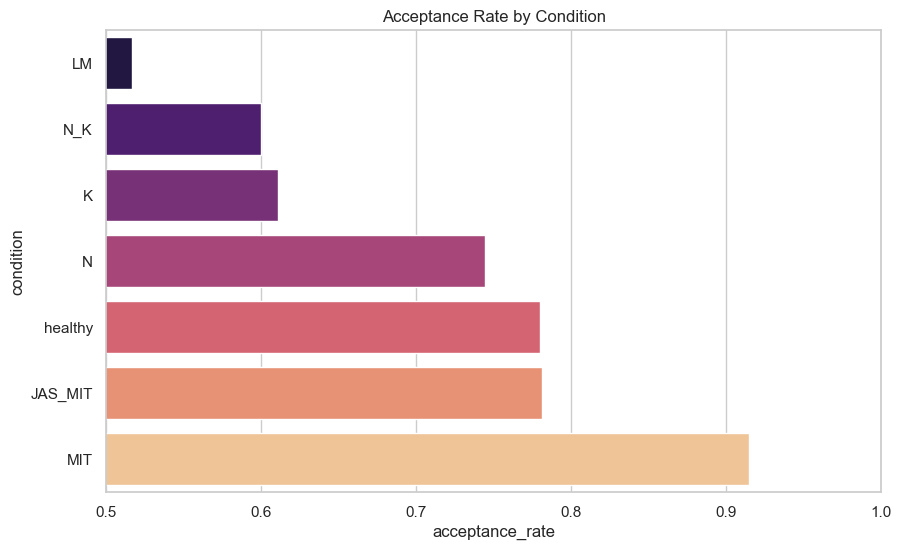

Observations: We check if severe necrosis or specific stress conditions are disproportionately excluded. Conditions with massive tissue death sometimes fail thresholding because the brown tissue blends with the dark background.


In [22]:
cond_stats = df.groupby('condition').size().reset_index(name='total_original')
cond_acc = df_accepted.groupby('condition').size().reset_index(name='accepted')
cond_exc = df_excluded.groupby('condition').size().reset_index(name='excluded')

cond_df = cond_stats.merge(cond_acc, on='condition', how='left').merge(cond_exc, on='condition', how='left')
cond_df = cond_df.fillna(0)
cond_df['acceptance_rate'] = cond_df['accepted'] / cond_df['total_original']
cond_df = cond_df.sort_values('acceptance_rate')

display(cond_df)
cond_df.to_csv(os.path.join(RESULTS_DIR, 'condition_acceptance_analysis.csv'), index=False)

plt.figure(figsize=(10, 6))
sns.barplot(data=cond_df, x='acceptance_rate', y='condition', palette='magma')
plt.title('Acceptance Rate by Condition')
plt.xlim(0.5, 1.0)
plt.show()

print("Observations: We check if severe necrosis or specific stress conditions are disproportionately excluded. Conditions with massive tissue death sometimes fail thresholding because the brown tissue blends with the dark background.")


---
## SECTION 6 — ORIGINAL VS ACCEPTED CLASS DISTRIBUTION
---


,class,original_count,accepted_count,excluded_count,acceptance_rate,accepted_percentage
2,tomato__LM,207,107,100,0.516908,51.690821
5,tomato__N_K,40,24,16,0.600000,60.000000
1,tomato__K,36,22,14,0.611111,61.111111
4,tomato__N,47,35,12,0.744681,74.468085
6,tomato__healthy,236,184,52,0.779661,77.966102
0,tomato__JAS_MIT,32,25,7,0.781250,78.125000
3,tomato__MIT,200,183,17,0.915000,91.500000


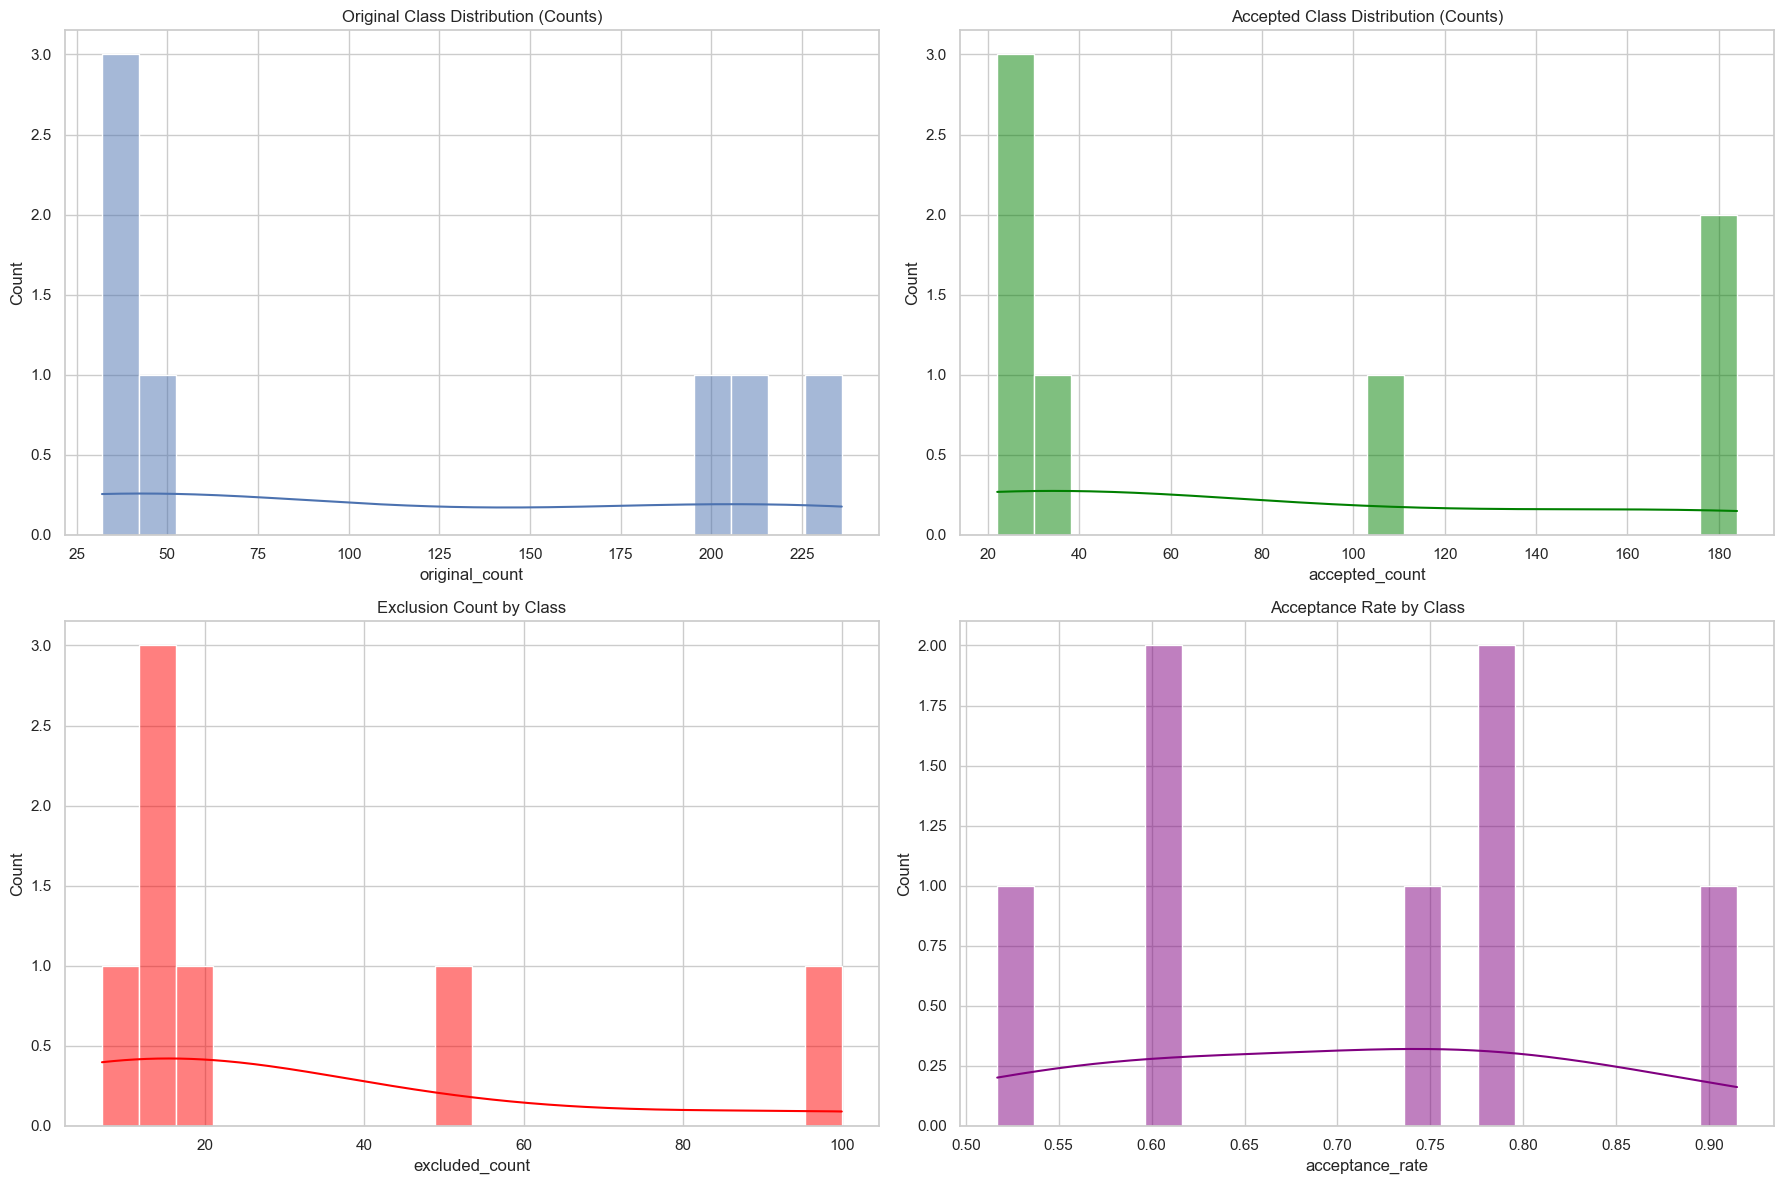

Classes with unusually low acceptance (<80%):


,class,original_count,accepted_count,acceptance_rate
2,tomato__LM,207,107,0.516908
5,tomato__N_K,40,24,0.600000
1,tomato__K,36,22,0.611111
4,tomato__N,47,35,0.744681
6,tomato__healthy,236,184,0.779661
0,tomato__JAS_MIT,32,25,0.781250


In [23]:
class_stats = df.groupby('class').size().reset_index(name='original_count')
class_acc = df_accepted.groupby('class').size().reset_index(name='accepted_count')
class_exc = df_excluded.groupby('class').size().reset_index(name='excluded_count')

cls_df = class_stats.merge(class_acc, on='class', how='left').merge(class_exc, on='class', how='left')
cls_df = cls_df.fillna(0)
cls_df['acceptance_rate'] = cls_df['accepted_count'] / cls_df['original_count']
cls_df['accepted_percentage'] = cls_df['acceptance_rate'] * 100
cls_df = cls_df.sort_values('acceptance_rate')

display(cls_df)
cls_df.to_csv(os.path.join(RESULTS_DIR, 'class_acceptance_analysis.csv'), index=False)

fig, axs = plt.subplots(2, 2, figsize=(18, 12))

sns.histplot(cls_df['original_count'], bins=20, ax=axs[0,0], kde=True)
axs[0,0].set_title('Original Class Distribution (Counts)')

sns.histplot(cls_df['accepted_count'], bins=20, ax=axs[0,1], kde=True, color='green')
axs[0,1].set_title('Accepted Class Distribution (Counts)')

sns.histplot(cls_df['excluded_count'], bins=20, ax=axs[1,0], kde=True, color='red')
axs[1,0].set_title('Exclusion Count by Class')

sns.histplot(cls_df['acceptance_rate'], bins=20, ax=axs[1,1], kde=True, color='purple')
axs[1,1].set_title('Acceptance Rate by Class')

plt.tight_layout()
plt.show()

worst_classes = cls_df[cls_df['acceptance_rate'] < 0.8]
if len(worst_classes) > 0:
    print("Classes with unusually low acceptance (<80%):")
    display(worst_classes[['class', 'original_count', 'accepted_count', 'acceptance_rate']])


---
## SECTION 7 — CROP × CONDITION ANALYSIS
---


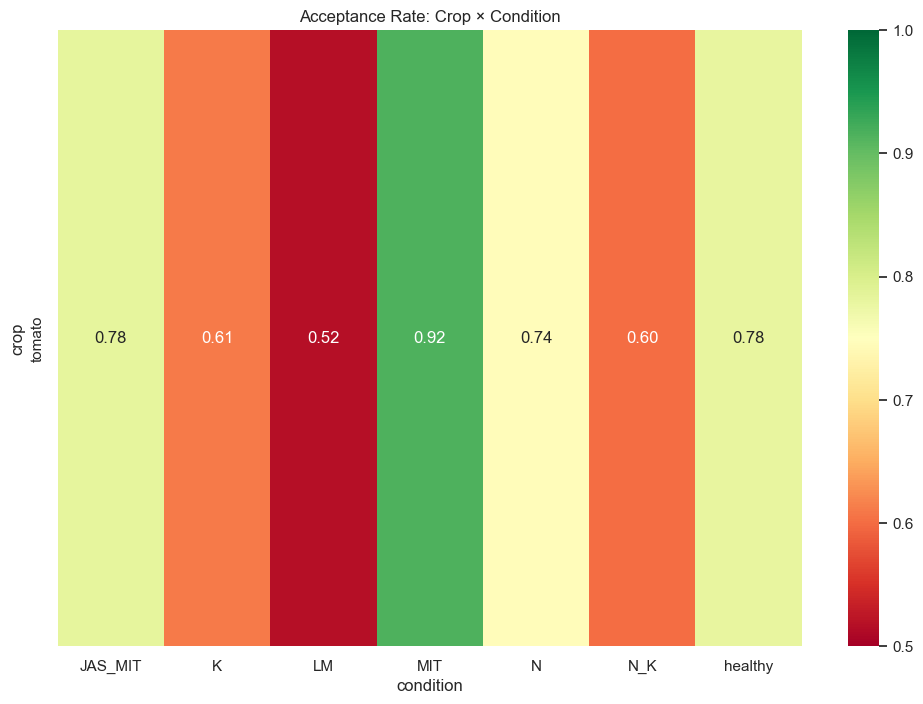

In [24]:
cc_stats = df.groupby(['crop', 'condition']).size().reset_index(name='original_count')
cc_acc = df_accepted.groupby(['crop', 'condition']).size().reset_index(name='accepted_count')
cc_exc = df_excluded.groupby(['crop', 'condition']).size().reset_index(name='excluded_count')

cc_df = cc_stats.merge(cc_acc, on=['crop', 'condition'], how='left').merge(cc_exc, on=['crop', 'condition'], how='left')
cc_df = cc_df.fillna(0)
cc_df['acceptance_rate'] = cc_df['accepted_count'] / cc_df['original_count']

cc_df.to_csv(os.path.join(RESULTS_DIR, 'crop_condition_acceptance.csv'), index=False)

pivot_acc = cc_df.pivot(index='crop', columns='condition', values='acceptance_rate')
plt.figure(figsize=(12, 8))
sns.heatmap(pivot_acc, annot=True, cmap='RdYlGn', vmin=0.5, vmax=1.0, fmt=".2f")
plt.title('Acceptance Rate: Crop × Condition')
plt.show()


---
## SECTION 8 — DUPLICATE / NEAR-DUPLICATE CHECK
---


In [25]:
print("DUPLICATE CHECK")
print("---------------")

dup_paths = df_accepted.duplicated(subset=['image_path']).sum()
print(f"1. Duplicate image_path: {dup_paths}")
if dup_paths > 0:
    print("WARNING: Duplicate image paths found!")

dup_names = df_accepted.duplicated(subset=['image_name']).sum()
print(f"2. Duplicate image_name: {dup_names}")

feature_cols = [c for c in df_accepted.columns if c not in meta_cols]
dup_feats = df_accepted.duplicated(subset=feature_cols).sum()
print(f"3. Duplicate feature rows: {dup_feats}")
if dup_feats > 0:
    print("WARNING: Exact identical feature vectors found! This likely means identical images exist under different filenames.")


DUPLICATE CHECK
---------------
1. Duplicate image_path: 0
2. Duplicate image_name: 0
3. Duplicate feature rows: 4


---
## SECTION 9 — MISSING VALUE ANALYSIS
---


In [26]:
missing_stats = []
for f in feature_cols:
    nas = df_accepted[f].isna().sum()
    infs = np.isinf(df_accepted[f]).sum()
    missing_stats.append({
        'feature': f,
        'missing_count': nas,
        'missing_percentage': (nas / len(df_accepted)) * 100,
        'infinite_count': infs
    })

miss_df = pd.DataFrame(missing_stats)
miss_df.to_csv(os.path.join(RESULTS_DIR, 'feature_quality_summary.csv'), index=False)

bad_features = miss_df[(miss_df['missing_count'] > 0) | (miss_df['infinite_count'] > 0)]
if len(bad_features) > 0:
    print("[WARNING] Features with Missing or Infinite values:")
    display(bad_features)
else:
    print("✅ No missing or infinite values detected in numerical features.")


✅ No missing or infinite values detected in numerical features.


---
## SECTION 10 — CONSTANT AND NEAR-CONSTANT FEATURES
---


In [27]:
stats_list = []
for f in feature_cols:
    val = df_accepted[f]
    stats_list.append({
        'feature': f,
        'unique_values': val.nunique(),
        'variance': val.var(),
        'std_dev': val.std(),
        'min': val.min(),
        'max': val.max()
    })

stat_df = pd.DataFrame(stats_list)
stat_df.to_csv(os.path.join(RESULTS_DIR, 'feature_statistics.csv'), index=False)

# Near constant definition: std < 1e-4
constant = stat_df[stat_df['std_dev'] == 0]
near_const = stat_df[(stat_df['std_dev'] > 0) & (stat_df['std_dev'] < 1e-4)]

if len(constant) > 0:
    print("Constant features:")
    display(constant)
else:
    print("No absolutely constant features.")

if len(near_const) > 0:
    print("\nNear-constant features (std < 1e-4):")
    display(near_const)
else:
    print("No near-constant features.")


No absolutely constant features.
No near-constant features.


---
## SECTION 11 — OUTLIER ANALYSIS
---


,feature,Q1,Q3,IQR,lower_bound,upper_bound,outlier_count,outlier_percentage
29,yellow_ratio,0.373528,0.379714,0.006186,0.364248,3.889931e-01,78,13.448276
37,edge_yellow_ratio,0.373476,0.380015,0.006539,0.363667,3.898246e-01,74,12.758621
18,mean_S,89.940786,101.530526,11.589740,72.556177,1.189151e+02,69,11.896552
35,core_yellow_ratio,0.372632,0.379494,0.006862,0.362339,3.897876e-01,65,11.206897
28,green_ratio,0.393131,0.403838,0.010707,0.377071,4.198974e-01,64,11.034483
24,mean_a,106.593840,108.920157,2.326317,103.104364,1.124096e+02,55,9.482759
16,mean_H,37.397392,39.452916,2.055524,34.314107,4.253620e+01,46,7.931034
36,edge_mean_H,37.274205,39.414206,2.140001,34.064204,4.262421e+01,43,7.413793
0,area,478820.875000,829727.625000,350906.750000,-47539.250000,1.356088e+06,40,6.896552
34,core_mean_H,37.583665,39.829803,2.246138,34.214458,4.319901e+01,38,6.551724


Note: Outliers in biological image features may represent true phenotypic variance rather than measurement errors. Do not delete them blindly.


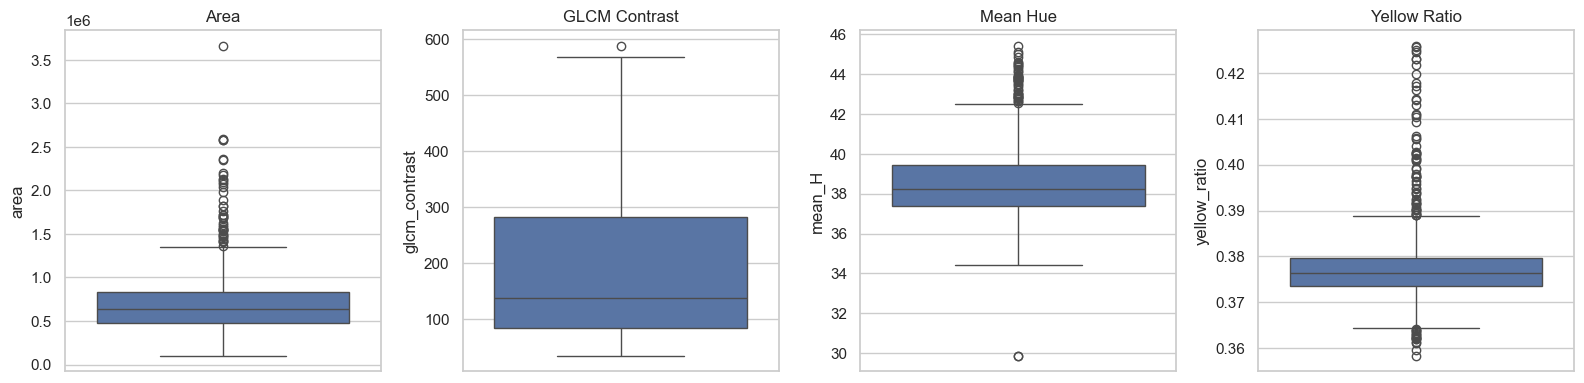

In [28]:
outlier_stats = []

for f in feature_cols:
    val = df_accepted[f]
    q1 = val.quantile(0.25)
    q3 = val.quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    
    outliers = val[(val < lower) | (val > upper)]
    
    outlier_stats.append({
        'feature': f,
        'Q1': q1,
        'Q3': q3,
        'IQR': iqr,
        'lower_bound': lower,
        'upper_bound': upper,
        'outlier_count': len(outliers),
        'outlier_percentage': (len(outliers) / len(val)) * 100
    })

out_df = pd.DataFrame(outlier_stats)
out_df.to_csv(os.path.join(RESULTS_DIR, 'feature_outlier_summary.csv'), index=False)
display(out_df.sort_values('outlier_percentage', ascending=False).head(10))

print("Note: Outliers in biological image features may represent true phenotypic variance rather than measurement errors. Do not delete them blindly.")

# Boxplots for a logical subset
fig, axs = plt.subplots(1, 4, figsize=(16, 4))
sns.boxplot(y=df_accepted['area'], ax=axs[0]).set_title('Area')
sns.boxplot(y=df_accepted['glcm_contrast'], ax=axs[1]).set_title('GLCM Contrast')
sns.boxplot(y=df_accepted['mean_H'], ax=axs[2]).set_title('Mean Hue')
sns.boxplot(y=df_accepted['yellow_ratio'], ax=axs[3]).set_title('Yellow Ratio')
plt.tight_layout()
plt.show()


---
## SECTION 12 — FEATURE DISTRIBUTIONS
---


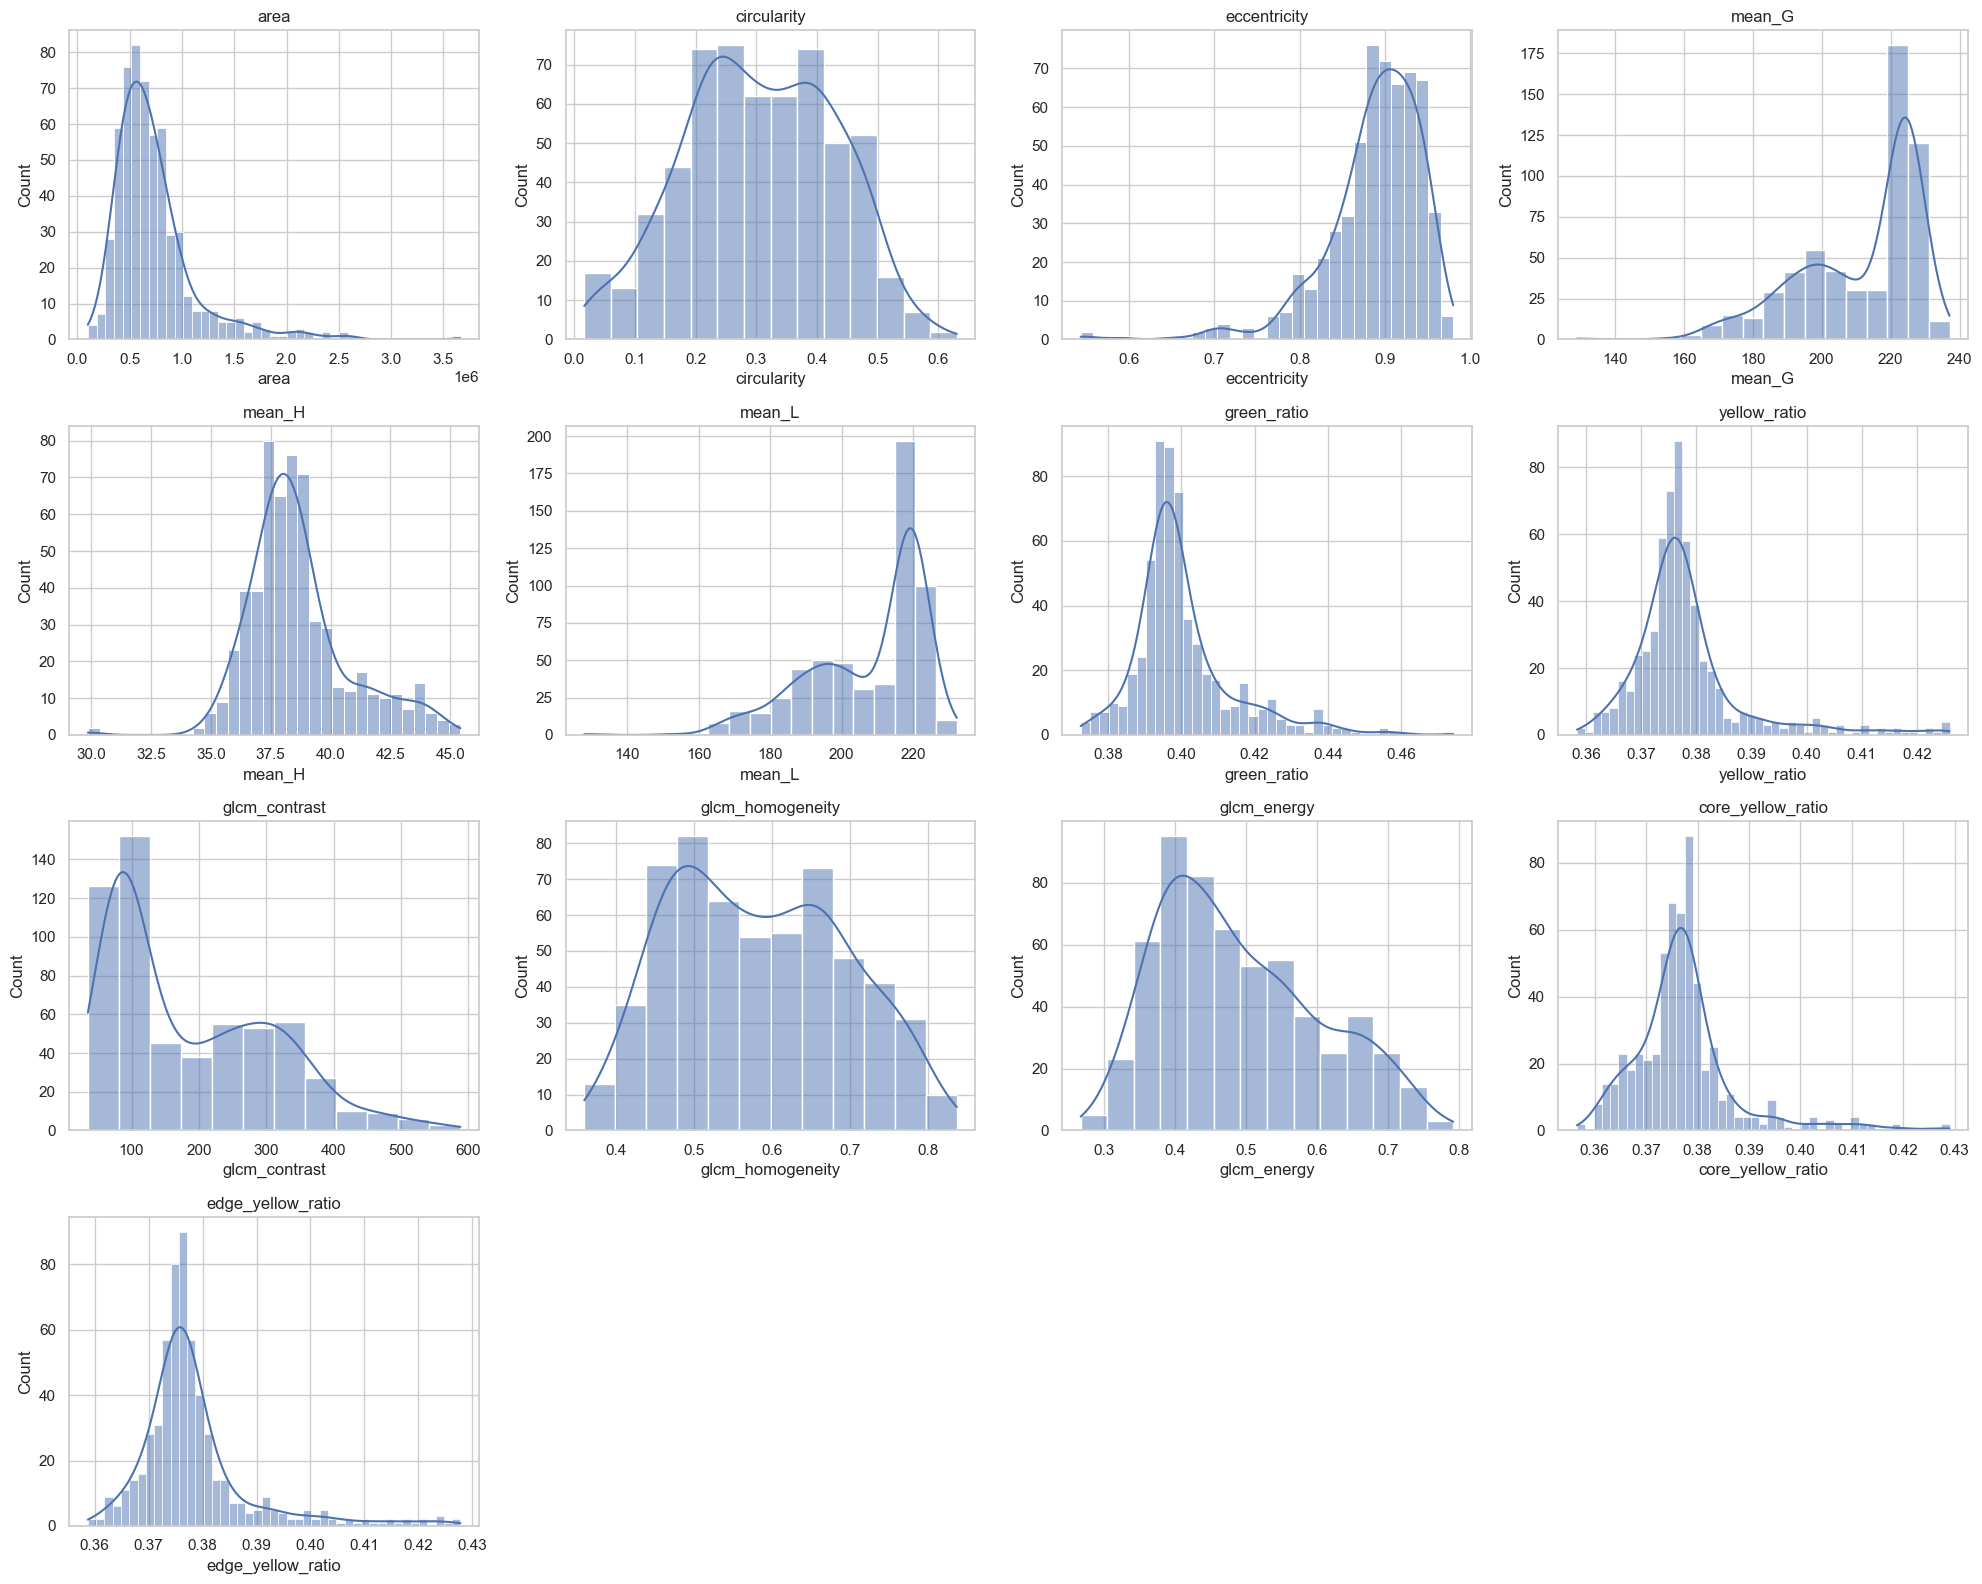

In [29]:
rep_features = [
    'area', 'circularity', 'eccentricity', 
    'mean_G', 'mean_H', 'mean_L', 'green_ratio', 'yellow_ratio',
    'glcm_contrast', 'glcm_homogeneity', 'glcm_energy',
    'core_yellow_ratio', 'edge_yellow_ratio'
]

fig, axs = plt.subplots(4, 4, figsize=(20, 16))
axs = axs.flatten()

for i, f in enumerate(rep_features):
    sns.histplot(df_accepted[f], kde=True, ax=axs[i])
    axs[i].set_title(f)

for j in range(i+1, 16):
    fig.delaxes(axs[j])

plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, 'feature_distributions.png'))
plt.show()


---
## SECTION 13 — FEATURE CORRELATION ANALYSIS
---


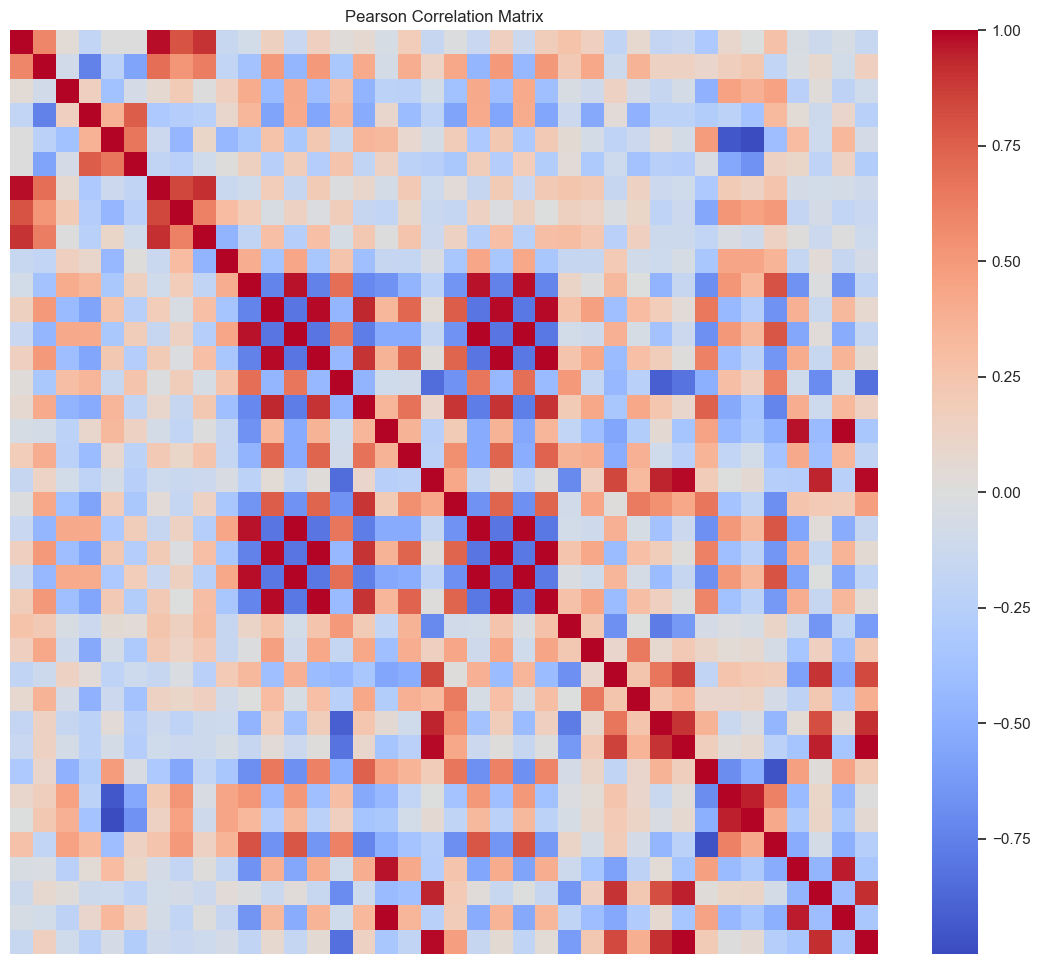

Found 36 highly correlated feature pairs (|r| >= 0.90).


,feature_1,feature_2,pearson_r,absolute_r
15,std_G,std_V,0.999985,0.999985
12,mean_G,mean_V,0.999966,0.999966
3,extent,glcm_energy,-0.999880,0.999880
16,std_G,std_L,0.999314,0.999314
26,std_V,std_L,0.999305,0.999305
25,mean_V,mean_L,0.998301,0.998301
13,mean_G,mean_L,0.998209,0.998209
20,mean_H,edge_mean_H,0.997905,0.997905
31,yellow_ratio,edge_yellow_ratio,0.996962,0.996962
10,std_R,std_V,0.991988,0.991988


Note: Do NOT remove features based solely on correlation. This analysis informs redundancy for the graph construction.


In [30]:
corr_matrix = df_accepted[feature_cols].corr(method='pearson')

plt.figure(figsize=(14, 12))
sns.heatmap(corr_matrix, cmap='coolwarm', center=0, xticklabels=False, yticklabels=False)
plt.title('Pearson Correlation Matrix')
plt.savefig(os.path.join(RESULTS_DIR, 'feature_correlation_heatmap.png'))
plt.show()

high_corr = []
for i in range(len(feature_cols)):
    for j in range(i+1, len(feature_cols)):
        r = corr_matrix.iloc[i, j]
        if abs(r) >= 0.90:
            high_corr.append({
                'feature_1': feature_cols[i],
                'feature_2': feature_cols[j],
                'pearson_r': r,
                'absolute_r': abs(r)
            })

hc_df = pd.DataFrame(high_corr).sort_values('absolute_r', ascending=False)
hc_df.to_csv(os.path.join(RESULTS_DIR, 'highly_correlated_pairs.csv'), index=False)

print(f"Found {len(hc_df)} highly correlated feature pairs (|r| >= 0.90).")
display(hc_df.head(10))
print("Note: Do NOT remove features based solely on correlation. This analysis informs redundancy for the graph construction.")


---
## SECTION 14 — FEATURE GROUP CORRELATIONS
---


In [ ]:
group_mean_corrs = []
groups = list(FEATURE_GROUPS.keys())

for i in range(len(groups)):
    for j in range(i, len(groups)):
        g1, g2 = groups[i], groups[j]
        f1 = [f for f in FEATURE_GROUPS[g1] if f in feature_cols]
        f2 = [f for f in FEATURE_GROUPS[g2] if f in feature_cols]
        
        if not f1 or not f2: continue
            
        sub_corr = corr_matrix.loc[f1, f2].abs().values.copy()
        if g1 == g2:
            # Exclude diagonal
            np.fill_diagonal(sub_corr, np.nan)
            
        mean_r = np.nanmean(sub_corr)
        group_mean_corrs.append({'Group_1': g1, 'Group_2': g2, 'Mean_Abs_R': mean_r})

gcorr_df = pd.DataFrame(group_mean_corrs).sort_values('Mean_Abs_R', ascending=False)
display(gcorr_df)
print("Observation: These represent statistical associations, not definitive biological relationships.")


ValueError: underlying array is read-only

---
## SECTION 15 — CLASS / CONDITION FEATURE SEPARABILITY
---


C:\Users\merug\AppData\Local\Temp\ipykernel_19804\1611596940.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=sub_df, x='condition', y=f, ax=axs[i], order=target_conds, palette='Set2')
C:\Users\merug\AppData\Local\Temp\ipykernel_19804\1611596940.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=sub_df, x='condition', y=f, ax=axs[i], order=target_conds, palette='Set2')
C:\Users\merug\AppData\Local\Temp\ipykernel_19804\1611596940.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=sub_df, x='condition', y=f, ax=axs

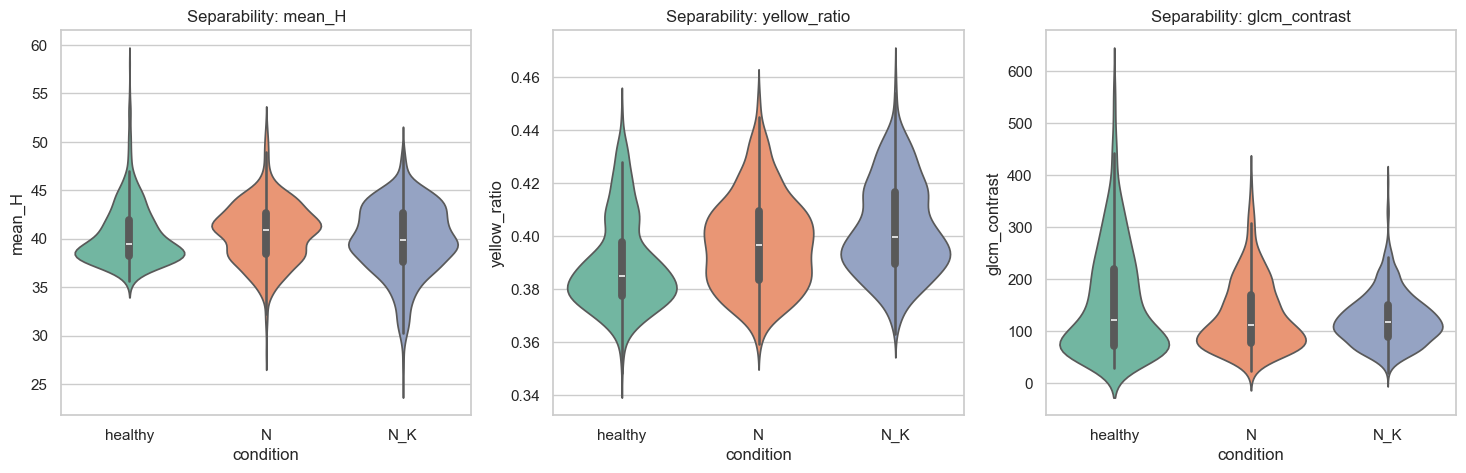

In [ ]:
example_features = ['mean_H', 'yellow_ratio', 'glcm_contrast']
target_conds = ['healthy', 'N', 'N_K']
sub_df = df_accepted[df_accepted['condition'].isin(target_conds)]

if len(sub_df) > 0:
    fig, axs = plt.subplots(1, 3, figsize=(18, 5))
    for i, f in enumerate(example_features):
        sns.violinplot(data=sub_df, x='condition', y=f, ax=axs[i], order=target_conds, palette='Set2')
        axs[i].set_title(f"Separability: {f}")
    plt.show()


---
## SECTION 16 — CHECK DATA LEAKAGE RISKS
---

**Leakage Risks for Final Experiments**

The full-dataset exploratory statistics in this notebook must **not** be used directly as fitted parameters for final cross-validation. 
To guarantee valid results, the following MUST be fitted strictly within the training folds during the final experiment:
1. Scaling (e.g. StandardScaler)
2. Discretization/bin boundaries (e.g. Quantile limits)
3. Correlation thresholds and graph edges (if learned dynamically)
4. Any feature selection
5. Any learned transformations (e.g. PCA)


---
## SECTION 17 — SAMPLE BALANCE REPORT
---


In [ ]:
class_sizes = df_accepted['class'].value_counts()

print("FINAL DATASET BALANCE REPORT")
print("----------------------------")
print(f"Total Accepted: {len(df_accepted)}")
print(f"Number of classes: {len(class_sizes)}")
print(f"Min class size: {class_sizes.min()}")
print(f"Max class size: {class_sizes.max()}")
print(f"Median class size: {class_sizes.median()}")
print(f"Mean class size: {class_sizes.mean():.1f}")
print(f"Class imbalance ratio (Max/Min): {class_sizes.max() / class_sizes.min():.2f}")

print("\nCrop Distribution:")
print(df_accepted['crop'].value_counts())

print("\nCondition Distribution:")
print(df_accepted['condition'].value_counts())


FINAL DATASET BALANCE REPORT
----------------------------
Total Accepted: 4387
Number of classes: 57
Min class size: 20
Max class size: 386
Median class size: 54.0
Mean class size: 77.0
Class imbalance ratio (Max/Min): 19.30

Crop Distribution:
crop
ash_gourd       996
bitter_gourd    742
eggplant        662
tomato          580
snake_gourd     452
ridge_gourd     383
bottle_gourd    332
cucumber        240
Name: count, dtype: int64

Condition Distribution:
condition
N_K         1010
healthy      713
N            673
K            584
MIT          257
N_Mg         219
LM           107
LS            95
MIT_EB        95
K_Mg          93
JAS           86
PM            78
DM            76
EB            73
PLEI          59
JAS_MIT       54
PLEI_IEM      37
FB            31
PC            27
PLEI_MIT      20
Name: count, dtype: int64


---
## SECTION 18 — FINAL DATASET READINESS CHECK
---


In [ ]:
checks = [
    {'check': 'Expected feature columns present', 'status': 'PASS' if total_verified == 38 else 'FAIL'},
    {'check': 'Accepted samples available', 'status': 'PASS' if len(df_accepted) > 0 else 'FAIL'},
    {'check': 'Image paths unique', 'status': 'PASS' if dup_paths == 0 else 'WARNING'},
    {'check': 'Missing values', 'status': 'PASS' if len(bad_features) == 0 else 'FAIL'},
    {'check': 'Constant features', 'status': 'PASS' if len(constant) == 0 else 'WARNING'},
    {'check': 'Severe class loss (>50% excluded)', 'status': 'PASS' if len(cls_df[cls_df['acceptance_rate'] < 0.5]) == 0 else 'WARNING'},
    {'check': 'Duplicate records', 'status': 'PASS' if dup_feats == 0 else 'WARNING'},
    {'check': 'Leakage precautions documented', 'status': 'PASS'}
]

chk_df = pd.DataFrame(checks)
display(chk_df)


,check,status
0,Expected feature columns present,PASS
1,Accepted samples available,PASS
2,Image paths unique,PASS
3,Missing values,PASS
4,Constant features,PASS
5,Severe class loss (>50% excluded),PASS
6,Duplicate records,WARNING
7,Leakage precautions documented,PASS


---
## SECTION 19 — SAVE OUTPUTS
---
(All CSV outputs were saved sequentially in RESULTS_DIR as they were generated.)


---
## SECTION 20 — FINAL RESEARCH INTERPRETATION
---


In [ ]:
print("FULL OLID-I FEATURE VALIDATION COMPLETE")
print("----------------------------------------")
print(f"Original samples: {total_processed}")
print(f"Accepted samples: {len(df_accepted)}")
print(f"Excluded samples: {len(df_excluded)}")
print(f"Acceptance rate: {(len(df_accepted)/total_processed)*100:.2f}%")
print(f"Classes: {df_accepted['class'].nunique()}")
print(f"Crops: {df_accepted['crop'].nunique()}")
print(f"Conditions: {df_accepted['condition'].nunique()}")
print(f"Numerical features: {total_verified}")

print("\nRecommendation:")
if chk_df['status'].isin(['FAIL']).any():
    print("- INVESTIGATE BEFORE PROCEEDING")
elif chk_df['status'].isin(['WARNING']).any():
    print("- PROCEED WITH CAUTION")
else:
    print("- PROCEED")


FULL OLID-I FEATURE VALIDATION COMPLETE
----------------------------------------
Original samples: 4749
Accepted samples: 4387
Excluded samples: 362
Acceptance rate: 92.38%
Classes: 57
Crops: 8
Conditions: 20
Numerical features: 38

Recommendation:
- PROCEED WITH CAUTION
